# Projet finance computationnelle 

# Tache 1 : 

On ne peut télécharger les données historiques de Yahoo finance car depuis 2024 les telechargements ont été résérvés aux abonnés payants .
    

In [4]:
!pip install -q yfinance
import yfinance as yhoof
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [5]:
donnees = yhoof.download("NVDA", start="2000-01-01", end="2024-12-31", auto_adjust=False)
Cours_cloture_adj = donnees["Adj Close"]

print(Cours_cloture_adj.head())
print (Cours_cloture_adj.tail())

[*********************100%***********************]  1 of 1 completed

Ticker          NVDA
Date                
2000-01-03  0.089206
2000-01-04  0.086825
2000-01-05  0.083966
2000-01-06  0.078487
2000-01-07  0.079798
Ticker            NVDA
Date                  
2024-12-23  139.305832
2024-12-24  139.854416
2024-12-26  139.565155
2024-12-27  136.652756
2024-12-30  137.131516


1- Nettoyer et inspecter le fichier :

In [6]:
Cours_cloture_adj.info()  #infos général

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6288 entries, 2000-01-03 to 2024-12-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   NVDA    6288 non-null   float64
dtypes: float64(1)
memory usage: 98.2 KB


In [7]:
Cours_cloture_adj.isna().sum()   #nbre de valeurs manquantes

Ticker
NVDA    0
dtype: int64

In [8]:
display(Cours_cloture_adj.min())
display(Cours_cloture_adj.max())

Ticker
NVDA    0.056178
dtype: float64

Ticker
NVDA    148.481583
dtype: float64

In [9]:
display(Cours_cloture_adj.index.min())
Cours_cloture_adj.index.max()

Timestamp('2000-01-03 00:00:00')

Timestamp('2024-12-30 00:00:00')

In [10]:
Cours_cloture_adj.agg(["min", "idxmin"])

Ticker,NVDA
min,0.056178
idxmin,2002-10-09 00:00:00


In [11]:
Cours_cloture_adj.agg(["max","idxmax"])

Ticker,NVDA
max,148.481583
idxmax,2024-11-07 00:00:00


2-Rendement disret et continu 
d'ici là on nomme dorénavant 
Cours_cloture_adj = St
Rendement discret =Rt
Rendement continu =rt

In [12]:
St = donnees["Adj Close"]

In [13]:
def Rendement_discret(St):
    i=1
    Rt=[]
    for i in range (1,len(St)):
       R =((St.iloc[i]-St.iloc[i-1])/St.iloc[i-1])*100
       Rt.append(R)
    return Rt
Rt=Rendement_discret(St)
print(Rt[:5])

[Ticker
NVDA   -2.670104
dtype: float64, Ticker
NVDA   -3.292173
dtype: float64, Ticker
NVDA   -6.525231
dtype: float64, Ticker
NVDA    1.669981
dtype: float64, Ticker
NVDA    3.282908
dtype: float64]


In [14]:
def Rendement_continu(St):
    i=1
    rt=[]
    for i in range (1,len(St)):
       R =(np.log(St.iloc[i])-np.log(St.iloc[i-1]))*100
       rt.append(R)
    return rt
rt=Rendement_continu(St)
print(rt[:5])

[Ticker
NVDA   -2.706399
dtype: float64, Ticker
NVDA   -3.347585
dtype: float64, Ticker
NVDA   -6.747864
dtype: float64, Ticker
NVDA    1.656191
dtype: float64, Ticker
NVDA    3.230172
dtype: float64]


2- Graphique et statistique : 

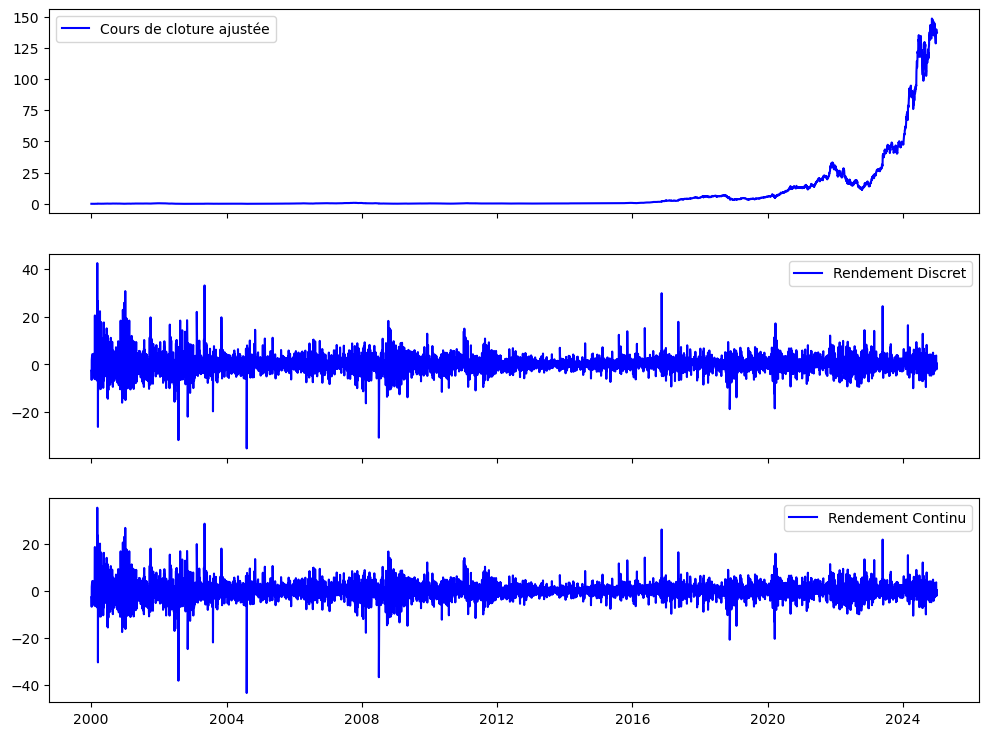

In [15]:
Rt_liste = Rendement_discret(St["NVDA"])
Rt = pd.Series(Rt_liste, index=St.index[1:])
rt_liste = Rendement_continu(St["NVDA"])
rt = pd.Series(rt_liste, index=St.index[1:])
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax1.plot(St.index,St, color="blue",label="Cours de cloture ajustée" )
ax2.plot(Rt.index,Rt, color="blue", label="Rendement Discret")
ax3.plot(rt.index,rt, color="blue", label="Rendement Continu")
ax1.legend()
ax2.legend()
ax3.legend()

In [16]:
rend = pd.DataFrame({"discret": Rt, "continu": rt})
rend.describe()

,discret,continu
count,6287.000000,6287.000000
mean,0.186319,0.116713
std,3.741624,3.728743
min,-35.233636,-43.438380
25%,-1.586897,-1.599623
50%,0.132365,0.132278
75%,1.798006,1.782033
max,42.414721,35.357318


In [17]:
rend = pd.DataFrame({"discret":Rt,"continue":rt,"Différence":Rt-rt,"Skew_dis":Rt.skew(),"skew_cont":rt.skew(),"kurt_dis":Rt.kurt(),"kurt_cont":rt.kurt()})
rend.head()


,discret,continue,Différence,Skew_dis,skew_cont,kurt_dis,kurt_cont
Date,,,,,,,
2000-01-04,-2.670104,-2.706399,0.036295,0.584619,-0.203069,12.080684,12.972198
2000-01-05,-3.292173,-3.347585,0.055412,0.584619,-0.203069,12.080684,12.972198
2000-01-06,-6.525231,-6.747864,0.222633,0.584619,-0.203069,12.080684,12.972198
2000-01-07,1.669981,1.656191,0.013791,0.584619,-0.203069,12.080684,12.972198
2000-01-10,3.282908,3.230172,0.052736,0.584619,-0.203069,12.080684,12.972198


Les jours normaux, les deux rendements disent la même chose. Volatilité quasi identique (3,74 % contre 3,73 % par jour), médianes et quartiles presque égaux. Pour de petites variations, le choix du rendement ne change rien.

Le rendement continu est en moyenne plus bas : 0,12 % par jour contre 0,19 %. C’est mécanique : le logarithme réduit toujours un rendement, et l’écart vaut à peu près la moitié de la variance.

Les deux divergent sur les journées extrêmes. Pire journée : −35 % en discret, −43 % en continu. Meilleure journée : +42 % contre +35 %. Le logarithme amplifie les fortes baisses et atténue les fortes hausses.

Du coup, l’asymétrie change de signe : +0,58 en discret, −0,20 en continu. La distribution paraît penchée vers les hausses ou vers les baisses selon la définition choisie. Conclusion : l’asymétrie dépend du type de rendement utilisé.

Les deux ont des queues très épaisses : kurtosis excédentaire de 12 et 13, alors qu’une loi normale vaut 0. Nvidia connaît beaucoup plus de journées extrêmes que ce que prévoit une loi normale. C’est le premier indice que l’hypothèse de normalité ne tient pas, ce que tes histogrammes confirmeront.

 les deux rendements sont équivalents pour les petites variations, mais pas pour les extrêmes, et dans les deux cas, la distribution est loin d’une loi normale.

3- Histogramme et densité normale 

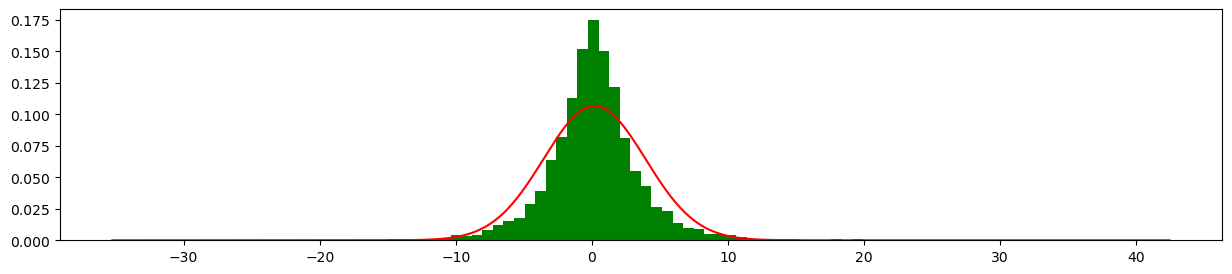

In [26]:
fig,ax=plt.subplots(figsize=(15,3))
Rt_liste = Rendement_discret(St["NVDA"])
Rt = pd.Series(Rt_liste, index=St.index[1:])

ax.hist(Rt,color="green", bins=100,density=True , label= "Rendement discret")
x = np.linspace(Rt.min(), Rt.max(), 500)
y = norm.pdf(x, Rt.mean(), Rt.std())
plt.plot(x, y, color="red")
plt.show()
ax.legend()


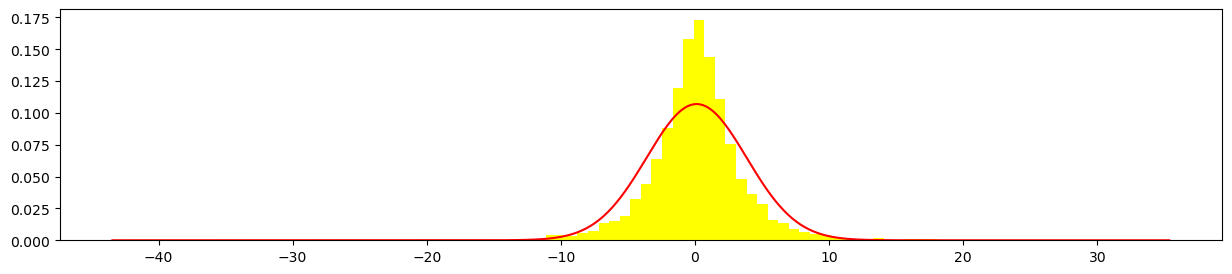

In [19]:
fig,ax=plt.subplots(figsize=(15,3))
rt_liste = Rendement_continu(St["NVDA"])
rt = pd.Series(rt_liste, index=St.index[1:])

ax.hist(rt,color="yellow", bins=100 ,density=True, label= "Rendement Continu ")
x = np.linspace(rt.min(), rt.max(), 500)
y = norm.pdf(x, rt.mean(), rt.std())
plt.plot(x, y, color="red")
plt.show()
ax.legend()

Non, l’hypothèse selon laquelle les rendements de Nvidia sont normalement distribués n’est pas raisonnable sur la période 2000-2024, que l’on considère les rendements discrets ou continus.

Ce que montrent les histogrammes , Comparée à la densité normale de même moyenne et de même variance, la distribution observée présente un pic central nettement plus élevé : les journées de faible variation sont beaucoup plus fréquentes que ne le prévoit la loi normale. À l’inverse, les variations intermédiaires sont moins fréquentes. Surtout, les queues de la distribution sont beaucoup plus épaisses : on observe des journées extrêmes, de −35 % à +42 % en rendement discret, là où la densité normale est pratiquement nulle. L’échelle logarithmique rend cet écart particulièrement visible. 

# Tache 2 :

In [19]:
#On récupère le cours de l'action actuel S0
donnees = yhoof.download("NVDA", start="2026-10-30", end="2026-10-31", auto_adjust=False)
S0 = donnees["Adj Close"]

print(S0.head())
date_cours="2026-10-30"
print(date_cours)

[*********************100%***********************]  1 of 1 completed

Ticker            NVDA
Date                  
2026-10-30  204.639999
2026-10-30


In [20]:
#Recupérer le put er le call
nvda = yhoof.Ticker("NVDA")
echeance = "2026-12-18"          # une date de la liste
chaine = nvda.option_chain(echeance)
calls = chaine.calls
puts = chaine.puts

calls.to_csv("NVDA_calls.csv")
puts.to_csv("NVDA_puts.csv")
print (calls[["strike","lastPrice","bid","ask","change","lastTradeDate"]].iloc[:5])
print (puts[["strike","lastPrice","bid","ask","change","lastTradeDate"]].iloc[:5])

   strike  lastPrice     bid     ask    change             lastTradeDate
0     0.5     205.24  200.55  208.60 -12.48999 2026-10-30 15:45:14+00:00
1     1.0     234.53  200.05  208.35   0.00000 2026-10-08 16:17:11+00:00
2     1.5     224.23    0.00    0.00   0.00000 2026-08-17 14:07:14+00:00
3     2.0     210.15    0.00    0.00   0.00000 2026-06-05 14:39:58+00:00
4     2.5     194.38  201.95  209.95   0.00000 2026-07-08 15:31:40+00:00
   strike  lastPrice  bid   ask  change             lastTradeDate
0     0.5       0.01  0.0  0.00     0.0 2026-09-03 13:32:32+00:00
1     1.0       0.01  0.0  0.01     0.0 2026-10-01 13:30:00+00:00
2     1.5       0.01  0.0  0.22     0.0 2026-07-15 13:36:19+00:00
3     2.0       0.07  0.0  0.00     0.0 2026-06-05 14:25:15+00:00
4     2.5       0.01  0.0  0.01     0.0 2026-08-04 13:42:08+00:00


In [21]:
#régler la fourchette
calls["mid"] = (calls["bid"] + calls["ask"]) / 2
puts["mid"] = (puts["bid"] + puts["ask"]) / 2
print(calls["mid"].iloc[:5])
print (puts["mid"].iloc[:5])

0    204.575
1    204.200
2      0.000
3      0.000
4    205.950
Name: mid, dtype: float64
0    0.000
1    0.005
2    0.110
3    0.000
4    0.005
Name: mid, dtype: float64


In [22]:
#récuperer le taux sans risque 
rf=pd.read_csv("DGS1.csv", index_col=0,parse_dates=True,na_values=".") 
rf.tail()

,DGS1
observation_date,
2026-10-23,4.44
2026-10-26,4.47
2026-10-27,4.50
2026-10-28,4.47
2026-10-29,4.42


In [23]:
#nettoyer donnée 
rf.info()
rf.isna().sum()
rf=rf.dropna()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 16913 entries, 1962-01-02 to 2026-10-29
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   DGS1    16192 non-null  float64
dtypes: float64(1)
memory usage: 264.3 KB


In [24]:
#prendre rf de la date précise
RF= rf.loc["2026-10-23"].iloc[0]
print(RF)
RF = np.log(1 + RF / 100)
print(RF)

4.44
0.043442557842836724


In [25]:
#calculer T 
T = (pd.Timestamp("2026-12-18" ) - pd.Timestamp( date_cours)).days / 365
print(T)

0.13424657534246576


In [28]:
#prendre le strike ATM 
S0=204.639999
position_atm = (calls["strike"] - S0).abs().idxmin()
position_Atm=(puts["strike"] - S0).abs().idxmin()
Kc = calls.loc[position_atm - 2 : position_atm + 2].copy()
Kp = puts.loc[position_Atm - 2 : position_Atm + 2].copy()
print(Kc[["strike","bid","ask"]])
print(Kp[["strike","bid","ask"]])

     strike    bid    ask
185   195.0  18.60  18.85
186   200.0  15.55  15.75
187   205.0  12.80  13.00
188   210.0  10.30  10.50
189   212.0   9.40   9.60
     strike    bid    ask
185   195.0   7.95   8.10
186   200.0   9.85  10.00
187   205.0  12.00  12.25
188   210.0  14.55  14.80
189   212.0  15.55  16.00


In [29]:
C= (Kc["bid"] + Kc["ask"]) / 2
P = (Kp["bid"] + Kp["ask"]) / 2
print(C)
print(P)

185    18.725
186    15.650
187    12.900
188    10.400
189     9.500
dtype: float64
185     8.025
186     9.925
187    12.125
188    14.675
189    15.775
dtype: float64


In [ ]:
#vérifier la parité : 

Les options sur actions américaines peuvent être exercées à tout moment avant l'échéance, pas seulement à la date finale. L'égalité devient alors un encadrement : S0 - D - K < C - P < S0 - K e^{-rT}

In [30]:
#calculons C-P
C_P=C-P
print(C_P)

185    10.700
186     5.725
187     0.775
188    -4.275
189    -6.275
dtype: float64


In [32]:
#calculons S0 - K e^{-rT} nommé A
A = S0-Kc["strike"]*(np.exp(-RF*T))
print(A)

185    10.773932
186     5.803007
187     0.832082
188    -4.138842
189    -6.127212
Name: strike, dtype: float64


In [33]:
#calculons S0-K nommé B( on néglige D car les dividendes sont minimes ) 
B=S0-Kc["strike"]
print(B)

185    9.639999
186    4.639999
187   -0.360001
188   -5.360001
189   -7.360001
Name: strike, dtype: float64


In [36]:
Parité = pd.DataFrame({ "C_P":C_P, " A" : A," B":B})
Parité

,C_P,A,B
185,10.700,10.773932,9.639999
186,5.725,5.803007,4.639999
187,0.775,0.832082,-0.360001
188,-4.275,-4.138842,-5.360001
189,-6.275,-6.127212,-7.360001


Réponse : Nous utilisons les options Nvidia (NVDA) d’échéance 18 décembre 2026, relevées à la clôture du vendredi 30 octobre 2026. Le cours de l’action est S₀ = 204,64 USD, et le temps jusqu’à l’échéance T = 0,134 an. Le taux sans risque est le rendement des bons du Trésor à 1 an (DGS1, FRED) soit 4.44 %, converti en taux continu r = 0,43. Les prix des options sont pris au milieu de la fourchette bid-ask, plus représentatif que le dernier prix échangé, parfois ancien. Les strikes étudiés sont le strike ATM, 205 USD, et les deux strikes inférieurs et supérieurs suivants : 195, 200, 210 et 212 USD.

La relation testée. Pour des options européennes sans dividende, la parité put-call s’écrit C − P = S₀ − K·e^(−rT). Or les options sur actions américaines, comme celles de Nvidia, peuvent être exercées avant l’échéance. La parité devient alors un encadrement : S₀ − D − K ≤ C − P ≤ S₀ − K·e^(−rT), où D est la valeur des dividendes versés avant l’échéance, supposée nulle ici car le dividende de Nvidia est négligeable.

Résultats: Pour les cinq strikes, la différence C − P observée sur le marché se situe entre les deux bornes. La parité put-call, dans sa forme adaptée aux options américaines, est donc respectée.

Conclusion. La parité put-call est respectée pour les cinq strikes étudiés. Aucune opportunité d’arbitrage n’apparaît, ce qui est cohérent avec l’efficience d’un marché d’options aussi liquide que celui de Nvidia